# 02 Simulation: VertexFleet synthetic world and baseline benchmarks

This notebook builds a fake but realistic fleet world, saves it to `data/synthetic/`, and benchmarks simple baselines for every reasoning family (search, CSP, logic, uncertainty, ML). Every random number comes from the seed in `configs/config.yaml`, so **Restart + Run All** always gives the same results.

Think of it as a flight simulator: the agent can crash here as often as it likes before it ever sees real data.

In [1]:
# Setup: find the project root, make src/ importable, load config and seed
import sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "configs" / "config.yaml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from settings import load_config, set_seed
CFG = load_config()
SEED = set_seed()
print("Ready:", ROOT, "| seed:", SEED)

Ready: c:\Users\David.satizabal001\Documents\ML-1 | seed: 42


In [2]:
import heapq
import time
from collections import deque

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (mean_squared_error, mean_absolute_error,
                             precision_score, recall_score, f1_score, roc_auc_score)

rng = np.random.default_rng(SEED)
SIM = CFG["simulation"]
N_VEHICLES, N_ZONES, N_DAYS = SIM["n_vehicles"], SIM["n_zones"], SIM["n_days"]
SYN = CFG["paths"]["data_synthetic"]
SYN.mkdir(parents=True, exist_ok=True)
RESULTS = []  # one dict per experiment, shown in section j
print(N_VEHICLES, "vehicles |", N_ZONES, "zones |", N_DAYS, "days")

50 vehicles | 8 zones | 90 days


## a. World generator

Five pieces, built in order:

1. **City map:** a 12 x 12 street grid with some blocked roads, 8 zone centers and 3 depots (used by the search benchmark).
2. **Weather:** daily rain chance and an hourly temperature curve.
3. **Demand:** hourly trips per zone = base level x time-of-day curve x weekday factor x rain effect, plus Poisson noise.
4. **Vehicle health:** a hidden Markov chain per vehicle per day (Healthy > Worn > Critical > Failed). Telemetry (vibration, engine temp, battery) is generated from the hidden state plus noise, so the agent only ever sees noisy symptoms, never the true state.
5. **Maintenance notes:** short text written at each service event, tied to the hidden state (used later for the NLP topic).

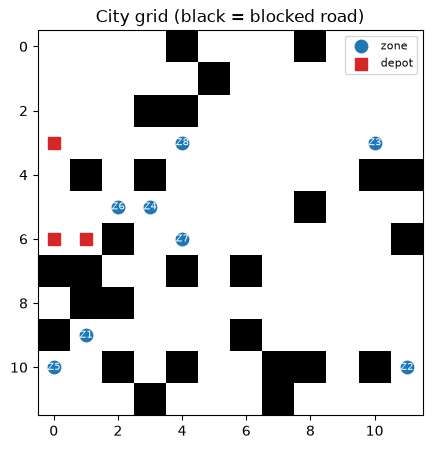

In [3]:
# 1. City map: grid with blocked cells, zone centers and depots
GRID = 12
blocked = rng.random((GRID, GRID)) < 0.18
free_cells = [(r, c) for r in range(GRID) for c in range(GRID)]
picks = rng.choice(len(free_cells), size=N_ZONES + 3, replace=False)
zone_cells = [free_cells[i] for i in picks[:N_ZONES]]
depot_cells = [free_cells[i] for i in picks[N_ZONES:]]
for cell in zone_cells + depot_cells:
    blocked[cell] = False  # zones and depots are always reachable cells
ZONES = [f"Z{i+1}" for i in range(N_ZONES)]
DEPOTS = [f"D{i+1}" for i in range(3)]
zone_map = pd.DataFrame({"zone": ZONES, "row": [c[0] for c in zone_cells], "col": [c[1] for c in zone_cells]})
depot_map = pd.DataFrame({"depot": DEPOTS, "row": [c[0] for c in depot_cells], "col": [c[1] for c in depot_cells]})

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(blocked, cmap="Greys")
ax.scatter(zone_map.col, zone_map.row, c="tab:blue", s=80, label="zone")
ax.scatter(depot_map.col, depot_map.row, c="tab:red", marker="s", s=80, label="depot")
for _, z in zone_map.iterrows():
    ax.annotate(z.zone, (z.col, z.row), color="white", ha="center", va="center", fontsize=7)
ax.set_title("City grid (black = blocked road)")
ax.legend(loc="upper right", fontsize=8)
plt.show()

In [4]:
# 2. Weather: one rain flag per day, hourly temperature
hours = pd.date_range("2026-01-01", periods=N_DAYS * 24, freq="h")
days = pd.date_range("2026-01-01", periods=N_DAYS, freq="D")
rain_day = rng.random(N_DAYS) < 0.3
weather = pd.DataFrame({"timestamp": hours})
weather["day"] = weather.timestamp.dt.normalize()
weather["rain"] = np.repeat(rain_day, 24).astype(int)
hour_of_day = weather.timestamp.dt.hour.to_numpy()
weather["temp_c"] = (24 + 5 * np.sin((hour_of_day - 9) / 24 * 2 * np.pi)
                     - 2 * weather.rain + rng.normal(0, 1.0, len(weather))).round(1)
weather = weather.drop(columns="day")
weather.head()

,timestamp,rain,temp_c
0,2026-01-01 00:00:00,0,19.9
1,2026-01-01 01:00:00,0,18.8
2,2026-01-01 02:00:00,0,19.1
3,2026-01-01 03:00:00,0,17.2
4,2026-01-01 04:00:00,0,17.7


In [5]:
# 3. Demand: hourly trips per zone
base = rng.uniform(4, 18, N_ZONES)                       # each zone's typical volume
hour_curve = (0.3 + np.exp(-((np.arange(24) - 8) ** 2) / 6)
              + 1.2 * np.exp(-((np.arange(24) - 17) ** 2) / 8))  # morning and evening peaks
rows = []
for t_idx, ts in enumerate(hours):
    weekday_factor = 0.8 if ts.dayofweek >= 5 else 1.0
    rain_factor = 1.3 if weather.rain.iloc[t_idx] else 1.0
    lam = base * hour_curve[ts.hour] * weekday_factor * rain_factor
    trips = rng.poisson(lam)
    for z, n in zip(ZONES, trips):
        rows.append((ts, z, int(n)))
trips = pd.DataFrame(rows, columns=["timestamp", "zone", "trips"])
trips["hour"] = trips.timestamp.dt.hour
trips["dayofweek"] = trips.timestamp.dt.dayofweek
trips = trips.merge(weather[["timestamp", "rain", "temp_c"]], on="timestamp")
print(trips.shape)
trips.head()

(17280, 7)


C:\Users\David.satizabal001\AppData\Local\Temp\ipykernel_28164\1544753798.py:7: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  weekday_factor = 0.8 if ts.dayofweek >= 5 else 1.0
C:\Users\David.satizabal001\AppData\Local\Temp\ipykernel_28164\1544753798.py:15: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  trips["dayofweek"] = trips.timestamp.dt.dayofweek


,timestamp,zone,trips,hour,dayofweek,rain,temp_c
0,2026-01-01,Z1,2,0,3,0,19.9
1,2026-01-01,Z2,4,0,3,0,19.9
2,2026-01-01,Z3,8,0,3,0,19.9
3,2026-01-01,Z4,1,0,3,0,19.9
4,2026-01-01,Z5,2,0,3,0,19.9


In [6]:
# 4. Vehicle health: hidden Markov chain per vehicle per day, telemetry from the hidden state
STATES = ["Healthy", "Worn", "Critical", "Failed"]
P_DRY = np.array([[0.95, 0.05, 0.00, 0.00],   # rows: today's state, cols: tomorrow's state
                  [0.00, 0.90, 0.09, 0.01],
                  [0.00, 0.00, 0.80, 0.20],
                  [0.00, 0.00, 0.00, 1.00]])
P_RAIN = np.array([[0.93, 0.07, 0.00, 0.00],  # rain adds road stress, so faster wear
                   [0.00, 0.86, 0.12, 0.02],
                   [0.00, 0.00, 0.74, 0.26],
                   [0.00, 0.00, 0.00, 1.00]])
VIB_MU, VIB_SD = [2.0, 3.2, 4.8, 6.5], 0.7      # vibration (mm/s) by hidden state
TEMP_MU, TEMP_SD = [88, 93, 101, 110], 3.0      # engine temp (C) by hidden state
SERVICE_INTERVAL = 30                            # scheduled service every ~30 days

vehicles = pd.DataFrame({
    "vehicle_id": [f"V{i+1:02d}" for i in range(N_VEHICLES)],
    "home_zone": rng.choice(ZONES, N_VEHICLES),
    "age_years": rng.integers(1, 9, N_VEHICLES),
})

tele_rows, service_rows = [], []
for _, v in vehicles.iterrows():
    state = 0 if v.age_years < 5 else rng.choice([0, 1], p=[0.6, 0.4])
    odometer = float(rng.uniform(20_000, 15_000 * v.age_years + 20_000))
    days_since_service = int(rng.integers(0, SERVICE_INTERVAL))
    battery = rng.uniform(0.85, 1.0)
    for d_idx, day in enumerate(days):
        km = rng.uniform(80, 220)
        odometer += km
        days_since_service += 1
        battery = max(0.4, battery - rng.uniform(0.0005, 0.002) - 0.002 * (state >= 2))
        tele_rows.append({
            "date": day, "vehicle_id": v.vehicle_id, "zone": v.home_zone, "age_years": int(v.age_years),
            "true_state": STATES[state],                 # hidden: never given to the agent
            "vibration": round(max(0.1, rng.normal(VIB_MU[state], VIB_SD)), 2),
            "engine_temp": round(rng.normal(TEMP_MU[state], TEMP_SD), 1),
            "battery_health": round(battery + rng.normal(0, 0.01), 3),
            "km_today": round(km, 1), "odometer": round(odometer),
            "days_since_service": days_since_service, "rain": int(rain_day[d_idx]),
        })
        # service events: a failure forces a repair; scheduled service resets health
        if state == 3 or days_since_service >= SERVICE_INTERVAL + rng.integers(-3, 4):
            service_rows.append({"date": day, "vehicle_id": v.vehicle_id,
                                 "service_type": "repair" if state == 3 else "scheduled",
                                 "state_before": STATES[state]})
            state, days_since_service = 0, 0
            continue
        P = P_RAIN if rain_day[d_idx] else P_DRY
        state = rng.choice(4, p=P[state])

telemetry = pd.DataFrame(tele_rows)
service_history = pd.DataFrame(service_rows)

# Label: does this vehicle reach Failed within the next 7 days?
telemetry = telemetry.sort_values(["vehicle_id", "date"]).reset_index(drop=True)
is_failed = (telemetry.true_state == "Failed").astype(int)
telemetry["fails_within_7d"] = (
    is_failed.groupby(telemetry.vehicle_id)
    .transform(lambda s: s[::-1].rolling(8, min_periods=1).max()[::-1]).astype(int))
telemetry.loc[telemetry.true_state == "Failed", "fails_within_7d"] = 1
print(telemetry.shape, "| services:", len(service_history))
telemetry.head()

(4500, 13) | services: 194


,date,vehicle_id,zone,age_years,true_state,vibration,engine_temp,battery_health,km_today,odometer,days_since_service,rain,fails_within_7d
0,2026-01-01,V01,Z1,1,Healthy,2.80,91.3,0.900,108.2,20889,4,0,0
1,2026-01-02,V01,Z1,1,Healthy,1.81,86.7,0.895,197.3,21086,5,1,0
2,2026-01-03,V01,Z1,1,Healthy,1.04,88.4,0.915,87.9,21174,6,0,0
3,2026-01-04,V01,Z1,1,Healthy,2.26,87.2,0.902,170.0,21344,7,0,0
4,2026-01-05,V01,Z1,1,Worn,3.67,91.8,0.886,159.8,21504,8,0,0


In [7]:
# 5. Maintenance notes: short text tied to the hidden state at each service event
TEMPLATES = {
    "Healthy":  ["Routine check, no issues found.", "All systems normal, scheduled service done.",
                 "Minor cleaning, vehicle in good shape."],
    "Worn":     ["Brake pads showing wear, monitor next visit.", "Slight vibration at highway speed.",
                 "Tires near replacement threshold."],
    "Critical": ["Strong vibration and overheating reported by driver.", "Engine running hot, coolant leak suspected.",
                 "Grinding noise from front axle, urgent attention needed."],
    "Failed":   ["Vehicle towed in, engine would not start.", "Breakdown on route, transmission failure.",
                 "Vehicle stopped mid-trip, severe overheating."],
}
URGENCY = {"Healthy": "low", "Worn": "medium", "Critical": "high", "Failed": "high"}
maintenance_notes = service_history.copy()
maintenance_notes["note"] = [rng.choice(TEMPLATES[s]) for s in maintenance_notes.state_before]
maintenance_notes["urgency"] = maintenance_notes.state_before.map(URGENCY)
maintenance_notes = maintenance_notes.drop(columns="state_before")
maintenance_notes.head()

,date,vehicle_id,service_type,note,urgency
0,2026-01-19,V01,repair,"Vehicle towed in, engine would not start.",high
1,2026-02-17,V01,scheduled,"Routine check, no issues found.",low
2,2026-03-14,V01,repair,"Vehicle stopped mid-trip, severe overheating.",high
3,2026-03-25,V01,repair,"Breakdown on route, transmission failure.",high
4,2026-01-02,V02,scheduled,"All systems normal, scheduled service done.",low


## b. Save the data

Five CSVs go to `data/synthetic/`. The hidden `true_state` column stays in telemetry for evaluation only; the agent's code must never read it.

In [8]:
TABLES = {"trips": trips, "telemetry": telemetry, "service_history": service_history,
          "weather": weather, "maintenance_notes": maintenance_notes}
for name, df in TABLES.items():
    df.to_csv(SYN / f"{name}.csv", index=False)
    print(f"saved {name}.csv  {df.shape}")
zone_map.to_csv(SYN / "zone_map.csv", index=False)
depot_map.to_csv(SYN / "depot_map.csv", index=False)
np.save(SYN / "blocked_grid.npy", blocked)
print("saved zone_map.csv, depot_map.csv, blocked_grid.npy")

saved trips.csv  (17280, 7)
saved telemetry.csv  (4500, 13)
saved service_history.csv  (194, 4)
saved weather.csv  (2160, 3)
saved maintenance_notes.csv  (194, 5)
saved zone_map.csv, depot_map.csv, blocked_grid.npy


## c. Load the data back

Everything below reads from the saved files, the same way later phases will. When a file is missing, the cell asks you for it (a file upload in Colab, a file picker in VS Code) instead of erroring.

In [9]:
def load_csv(name, parse_dates=None):
    path = SYN / f"{name}.csv"
    if path.exists():
        return pd.read_csv(path, parse_dates=parse_dates)
    print(f"{path} not found; please choose the file.")
    try:
        from google.colab import files  # Colab
        uploaded = files.upload()
        import io
        return pd.read_csv(io.BytesIO(next(iter(uploaded.values()))), parse_dates=parse_dates)
    except ImportError:
        import tkinter as tk
        from tkinter import filedialog
        root = tk.Tk(); root.withdraw(); root.attributes("-topmost", True)
        chosen = filedialog.askopenfilename(title=f"Select {name}.csv", filetypes=[("CSV", "*.csv")])
        root.destroy()
        return pd.read_csv(chosen, parse_dates=parse_dates)

trips = load_csv("trips", ["timestamp"])
telemetry = load_csv("telemetry", ["date"])
service_history = load_csv("service_history", ["date"])
weather = load_csv("weather", ["timestamp"])
maintenance_notes = load_csv("maintenance_notes", ["date"])
print({n: len(df) for n, df in [("trips", trips), ("telemetry", telemetry), ("service", service_history),
                                 ("weather", weather), ("notes", maintenance_notes)]})

{'trips': 17280, 'telemetry': 4500, 'service': 194, 'weather': 2160, 'notes': 194}


## d. Exploratory data analysis

Four questions: When is demand high? Which zones are busiest? Does telemetry actually separate the hidden health states? How rare are failures (class balance)?

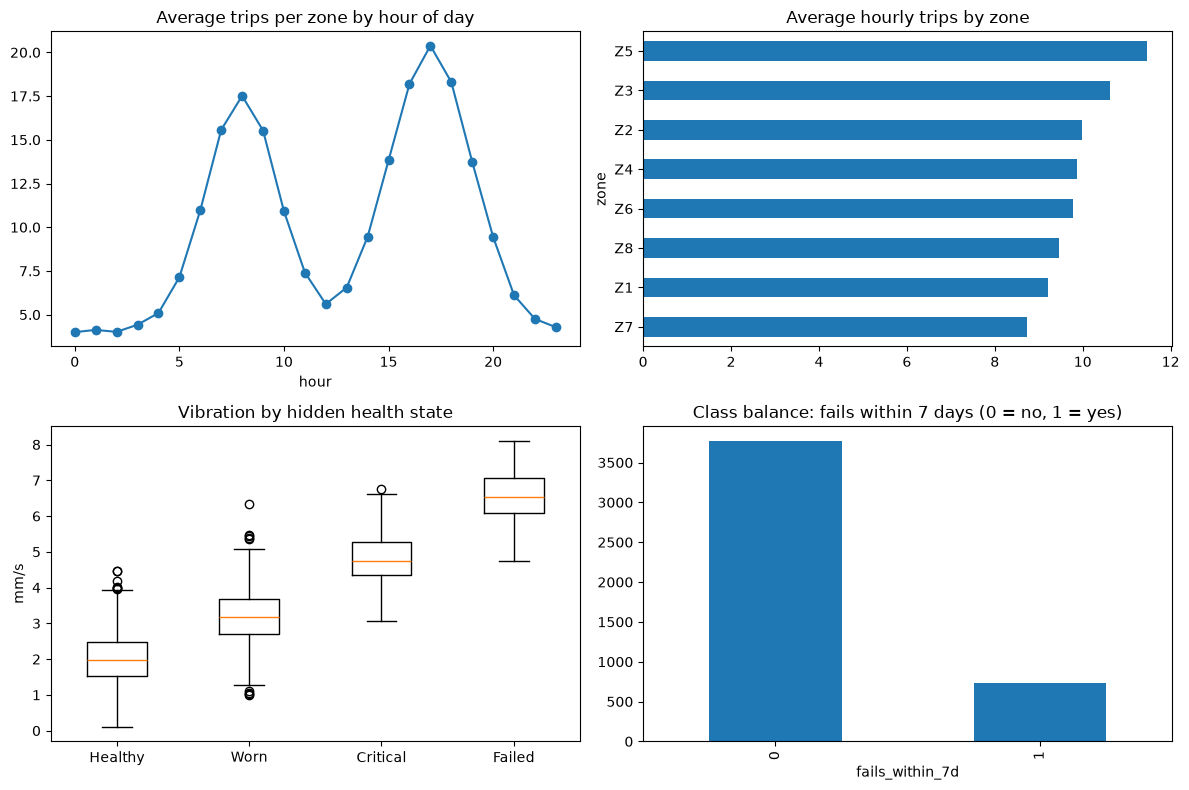

Rain raises average demand by 37%
Positive class share: 16.3%


In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

trips.groupby("hour").trips.mean().plot(ax=axes[0, 0], marker="o")
axes[0, 0].set_title("Average trips per zone by hour of day"); axes[0, 0].set_xlabel("hour")

trips.groupby("zone").trips.mean().sort_values().plot.barh(ax=axes[0, 1])
axes[0, 1].set_title("Average hourly trips by zone")

order = ["Healthy", "Worn", "Critical", "Failed"]
data = [telemetry.loc[telemetry.true_state == s, "vibration"] for s in order]
axes[1, 0].boxplot(data, tick_labels=order)
axes[1, 0].set_title("Vibration by hidden health state"); axes[1, 0].set_ylabel("mm/s")

telemetry.fails_within_7d.value_counts().sort_index().plot.bar(ax=axes[1, 1])
axes[1, 1].set_title("Class balance: fails within 7 days (0 = no, 1 = yes)")
plt.tight_layout(); plt.show()

rain_effect = trips.groupby("rain").trips.mean()
print(f"Rain raises average demand by {rain_effect[1] / rain_effect[0] - 1:.0%}")
print(f"Positive class share: {telemetry.fails_within_7d.mean():.1%}")

## e. Search benchmark: route a vehicle to the nearest depot

Same question, three algorithms. BFS explores evenly in all directions (like ripples in a pond). Greedy best-first rushes toward the goal and can take a worse path. A* balances distance travelled so far with a Manhattan-distance estimate of what is left, so it finds the shortest path while expanding fewer cells than BFS.

In [11]:
blocked = np.load(SYN / "blocked_grid.npy")
zone_map = pd.read_csv(SYN / "zone_map.csv")
depot_map = pd.read_csv(SYN / "depot_map.csv")
DEPOT_CELLS = {(r, c) for r, c in zip(depot_map.row, depot_map.col)}

def neighbors(cell):
    r, c = cell
    for dr, dc in [(1, 0), (-1, 0), (0, 1), (0, -1)]:
        nr, nc = r + dr, c + dc
        if 0 <= nr < GRID and 0 <= nc < GRID and not blocked[nr, nc]:
            yield (nr, nc)

def h(cell):  # admissible heuristic: Manhattan distance to the closest depot
    return min(abs(cell[0] - d[0]) + abs(cell[1] - d[1]) for d in DEPOT_CELLS)

def bfs(start):
    frontier, parent, expanded = deque([start]), {start: None}, 0
    while frontier:
        cell = frontier.popleft(); expanded += 1
        if cell in DEPOT_CELLS:
            return path_len(parent, cell), expanded
        for n in neighbors(cell):
            if n not in parent:
                parent[n] = cell; frontier.append(n)
    return None, expanded

def best_first(start, use_g):
    """use_g=False -> greedy best-first (f = h); use_g=True -> A* (f = g + h)."""
    frontier, g, parent, expanded, closed = [(h(start), 0, start)], {start: 0}, {start: None}, 0, set()
    while frontier:
        _, _, cell = heapq.heappop(frontier)
        if cell in closed:
            continue
        closed.add(cell); expanded += 1
        if cell in DEPOT_CELLS:
            return g[cell], expanded
        for n in neighbors(cell):
            new_g = g[cell] + 1
            if n not in g or new_g < g[n]:
                g[n], parent[n] = new_g, cell
                f = new_g + h(n) if use_g else h(n)
                heapq.heappush(frontier, (f, new_g, n))
    return None, expanded

def path_len(parent, cell):
    n = 0
    while parent[cell] is not None:
        cell = parent[cell]; n += 1
    return n

rows = []
for _, z in zone_map.iterrows():
    start = (z.row, z.col)
    for name, fn in [("BFS", bfs), ("Greedy", lambda s: best_first(s, False)), ("A*", lambda s: best_first(s, True))]:
        t0 = time.perf_counter(); cost, expanded = fn(start); ms = (time.perf_counter() - t0) * 1000
        rows.append({"zone": z.zone, "algorithm": name, "path_cost": cost, "nodes_expanded": expanded, "ms": round(ms, 3)})
search_df = pd.DataFrame(rows)
summary = search_df.groupby("algorithm")[["path_cost", "nodes_expanded", "ms"]].mean().round(2)
optimal = search_df.pivot(index="zone", columns="algorithm", values="path_cost")
summary["optimal_rate"] = [(optimal[a] == optimal["BFS"]).mean() for a in summary.index]
display(summary)

for alg in ["BFS", "Greedy", "A*"]:
    RESULTS.append({"Hypothesis": "A* finds optimal routes with fewer expansions than BFS",
                    "Method": f"Search: {alg}", "Metric": "avg nodes expanded / optimal rate",
                    "Result": f"{summary.loc[alg, 'nodes_expanded']} / {summary.loc[alg, 'optimal_rate']:.0%}",
                    "Failure cases": ("Unreachable zone returns no path" if search_df[search_df.algorithm == alg].path_cost.isna().any()
                                      else f"Suboptimal path in {1 - summary.loc[alg, 'optimal_rate']:.0%} of zones" if summary.loc[alg, "optimal_rate"] < 1
                                      else "None on this map; greedy has no optimality guarantee" if alg == "Greedy"
                                      else "None observed")})

,path_cost,nodes_expanded,ms,optimal_rate
algorithm,,,,
A*,7.5,15.62,0.04,1.0
BFS,7.5,44.25,0.04,1.0
Greedy,7.5,9.25,0.03,1.0


## f. CSP benchmark: assign flagged vehicles to service bays and shifts

**Variables:** the vehicles flagged for service. **Domain:** (depot, shift) slots. **Constraints:** each depot has one technician per shift, so at most one vehicle per (depot, shift); urgent vehicles must be seen in shift 1 or 2; a vehicle can only use a depot at most 3 blocks farther than its nearest depot.

Plain backtracking tries variables in a fixed order. MRV (minimum remaining values) always picks the vehicle with the fewest legal options left, like seating the pickiest wedding guests first. We count how many assignments each tries.

In [12]:
SHIFTS = [1, 2, 3]
zone_xy = {z.zone: (z.row, z.col) for _, z in zone_map.iterrows()}
depot_xy = {d.depot: (d.row, d.col) for _, d in depot_map.iterrows()}
def dist(zone, depot):
    (a, b), (c, d) = zone_xy[zone], depot_xy[depot]
    return abs(a - c) + abs(b - d)
EXTRA_TRAVEL = 3   # a vehicle may use any depot at most 3 blocks farther than its nearest depot
N_FLAGGED = 9      # 9 vehicles for 9 (depot, shift) slots: a tight puzzle

def build_domains(day):
    snap = telemetry[telemetry.date == day].copy()
    snap["risk"] = snap.vibration + (snap.engine_temp - 88) / 5
    flagged = snap.nlargest(N_FLAGGED, "risk").reset_index(drop=True)
    flagged["urgent"] = flagged.vibration > 4.5   # urgent if vibration looks Critical
    domains = {}
    for _, v in flagged.iterrows():
        shifts = [1, 2] if v.urgent else SHIFTS
        nearest = min(dist(v.zone, d) for d in depot_xy)
        domains[v.vehicle_id] = [(d, s) for d in depot_xy for s in shifts if dist(v.zone, d) <= nearest + EXTRA_TRAVEL]
    return flagged, domains

def backtrack(assign, domains, use_mrv, counter):
    if len(assign) == len(domains):
        return dict(assign)
    unassigned = [v for v in domains if v not in assign]
    used = set(assign.values())
    if use_mrv:
        var = min(unassigned, key=lambda v: sum(1 for x in domains[v] if x not in used))
    else:
        var = unassigned[0]
    for value in domains[var]:
        if value in used:          # one technician per (depot, shift)
            continue
        counter[0] += 1
        assign[var] = value
        result = backtrack(assign, domains, use_mrv, counter)
        if result:
            return result
        del assign[var]
    return None

# Benchmark over the last 30 days: one scheduling puzzle per day
csp_rows = []
for day in sorted(telemetry.date.unique())[-30:]:
    flagged, domains = build_domains(day)
    for label, mrv in [("Plain backtracking", False), ("Backtracking + MRV", True)]:
        counter = [0]
        t0 = time.perf_counter(); solution = backtrack({}, domains, mrv, counter); ms = (time.perf_counter() - t0) * 1000
        csp_rows.append({"day": day, "solver": label, "solved": solution is not None,
                         "assignments_tried": counter[0], "ms": ms})
csp_df = pd.DataFrame(csp_rows)
csp_summary = csp_df.groupby("solver").agg(solve_rate=("solved", "mean"),
                                           avg_assignments=("assignments_tried", "mean"),
                                           max_assignments=("assignments_tried", "max"),
                                           avg_ms=("ms", "mean")).round(2)
display(csp_summary)
unsolvable = int((~csp_df[csp_df.solver == "Backtracking + MRV"].solved).sum())
for label in csp_summary.index:
    RESULTS.append({"Hypothesis": "MRV reduces assignments tried", "Method": f"CSP: {label}",
                    "Metric": "avg / max assignments tried (30 daily puzzles)",
                    "Result": f"{csp_summary.loc[label, 'avg_assignments']} / {csp_summary.loc[label, 'max_assignments']}",
                    "Failure cases": f"{unsolvable} of 30 days have no feasible schedule under the shift and travel limits; the agent must escalate those to a human" if unsolvable else "None observed"})

# Show one day's schedule
flagged, domains = build_domains(telemetry.date.max())
solution = backtrack({}, domains, True, [0])
print("Last day, urgent vehicles:", int(flagged.urgent.sum()), "| schedule:", solution)

try:  # optional cross-check with the python-constraint library
    import constraint
    prob = constraint.Problem()
    for v, dom in domains.items():
        prob.addVariable(v, dom)
    prob.addConstraint(constraint.AllDifferentConstraint())
    print("python-constraint agrees a solution exists:", prob.getSolution() is not None)
except ImportError:
    print("python-constraint not installed; skipping cross-check")

,solve_rate,avg_assignments,max_assignments,avg_ms
solver,,,,
Backtracking + MRV,0.73,166.63,3232,0.44
Plain backtracking,0.73,460.03,3274,0.45


Last day, urgent vehicles: 2 | schedule: {'V28': ('D1', 1), 'V17': ('D1', 2), 'V37': ('D1', 3), 'V08': ('D3', 1), 'V20': ('D3', 2), 'V24': ('D2', 1), 'V38': ('D2', 2), 'V13': ('D2', 3), 'V43': ('D3', 3)}
python-constraint agrees a solution exists: True


## Time-based split (used by g, h and i)

Train on the first 70 days, test on the rest. A random split would let the model peek at the future, like studying with tomorrow's answer key.

In [13]:
SPLIT_DATE = telemetry.date.min() + pd.Timedelta(days=70)
FEATURES = ["vibration", "engine_temp", "battery_health", "days_since_service", "age_years", "rain"]
train = telemetry[telemetry.date < SPLIT_DATE]
test = telemetry[telemetry.date >= SPLIT_DATE]
X_train, y_train = train[FEATURES], train.fails_within_7d
X_test, y_test = test[FEATURES], test.fails_within_7d
print(f"train {len(train)} rows ({y_train.mean():.1%} positive) | test {len(test)} rows ({y_test.mean():.1%} positive)")

def clf_report(name, y_true, y_pred, y_score=None):
    out = {"precision": precision_score(y_true, y_pred, zero_division=0),
           "recall": recall_score(y_true, y_pred, zero_division=0),
           "f1": f1_score(y_true, y_pred, zero_division=0)}
    if y_score is not None:
        out["roc_auc"] = roc_auc_score(y_true, y_score)
    print(name, {k: round(v, 3) for k, v in out.items()})
    return out

train 3500 rows (16.9% positive) | test 1000 rows (14.1% positive)


## g. Logic baseline: hand-written rules only

Two Horn-style rules, no learning: `HighVibration(v) AND OverdueService(v) => NeedsInspection(v)` and `EngineHot(v) => NeedsInspection(v)`. Thresholds come from `config.yaml` style constants so they can be tuned without touching the logic.

In [14]:
RULE_VIB, RULE_DAYS, RULE_TEMP = 4.0, 20, 100.0
rule_pred = (((X_test.vibration > RULE_VIB) & (X_test.days_since_service > RULE_DAYS))
             | (X_test.engine_temp > RULE_TEMP)).astype(int)
logic = clf_report("Logic rules", y_test, rule_pred)
missed = test[(rule_pred == 0) & (y_test == 1)]
missed_states = missed.true_state.value_counts(normalize=True)
print("Hidden state of missed failures:", missed_states.round(2).to_dict())
RESULTS.append({"Hypothesis": "Simple rules catch most upcoming failures",
                "Method": "Logic: 2 Horn rules", "Metric": "precision / recall",
                "Result": f"{logic['precision']:.2f} / {logic['recall']:.2f}",
                "Failure cases": f"{len(missed)} missed failures; {missed_states.iloc[0]:.0%} were {missed_states.index[0]} vehicles whose telemetry still looked normal"})

Logic rules {'precision': 0.685, 'recall': 0.447, 'f1': 0.541}
Hidden state of missed failures: {'Worn': 0.54, 'Healthy': 0.26, 'Critical': 0.21}


## h. Uncertainty baseline: Gaussian naive Bayes

Naive Bayes treats each sensor as independent evidence and combines them with Bayes' rule, so it outputs a probability instead of a yes/no. It is the simplest probabilistic model and the warm-up for the Bayesian network in Phase 3.

In [15]:
nb = GaussianNB().fit(X_train, y_train)
nb_score = nb.predict_proba(X_test)[:, 1]
nb_res = clf_report("Naive Bayes", y_test, (nb_score >= 0.5).astype(int), nb_score)
RESULTS.append({"Hypothesis": "Probabilities from telemetry beat fixed rules",
                "Method": "Uncertainty: Gaussian naive Bayes", "Metric": "precision / recall / ROC AUC",
                "Result": f"{nb_res['precision']:.2f} / {nb_res['recall']:.2f} / {nb_res['roc_auc']:.2f}",
                "Failure cases": "Independence assumption double-counts correlated vibration and temperature; overconfident probabilities"})

Naive Bayes {'precision': 0.656, 'recall': 0.582, 'f1': 0.617, 'roc_auc': 0.847}


## i. ML baselines

**Demand:** predict each zone-hour with the training-period average for that zone, hour and weekday-or-weekend. Any fancier model in Phase 3 must beat this.

**Failure:** logistic regression on scaled telemetry, with class weights to handle the imbalance.

In [16]:
trips["is_weekend"] = (trips.dayofweek >= 5).astype(int)
tr = trips[trips.timestamp < SPLIT_DATE]
te = trips[trips.timestamp >= SPLIT_DATE].copy()
means = tr.groupby(["zone", "hour", "is_weekend"]).trips.mean().rename("pred")
te = te.join(means, on=["zone", "hour", "is_weekend"])
rmse = mean_squared_error(te.trips, te.pred) ** 0.5
mae = mean_absolute_error(te.trips, te.pred)
rain_err = te.assign(err=(te.trips - te.pred).abs()).groupby("rain").err.mean()
print(f"Mean-by-zone-hour demand baseline: RMSE {rmse:.2f} | MAE {mae:.2f}")
print(f"MAE on dry hours {rain_err[0]:.2f} vs rainy hours {rain_err[1]:.2f}")
RESULTS.append({"Hypothesis": "Historical averages give a usable demand forecast",
                "Method": "ML: mean by zone/hour/weekend", "Metric": "RMSE / MAE",
                "Result": f"{rmse:.2f} / {mae:.2f}",
                "Failure cases": f"Ignores rain: MAE rises from {rain_err[0]:.2f} (dry) to {rain_err[1]:.2f} (rain)"})

logreg = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED))
logreg.fit(X_train, y_train)
lr_score = logreg.predict_proba(X_test)[:, 1]
lr_res = clf_report("Logistic regression", y_test, (lr_score >= 0.5).astype(int), lr_score)
RESULTS.append({"Hypothesis": "A linear model on telemetry predicts 7-day failure",
                "Method": "ML: logistic regression (balanced)", "Metric": "precision / recall / ROC AUC",
                "Result": f"{lr_res['precision']:.2f} / {lr_res['recall']:.2f} / {lr_res['roc_auc']:.2f}",
                "Failure cases": "Balanced weights raise recall but create many false alarms (low precision)"})

Mean-by-zone-hour demand baseline: RMSE 3.53 | MAE 2.68
MAE on dry hours 2.54 vs rainy hours 3.03
Logistic regression {'precision': 0.498, 'recall': 0.709, 'f1': 0.585, 'roc_auc': 0.865}


## j. Results table

One row per experiment. This is the baseline every Phase 3 model must beat, and it is saved to `data/processed/phase1_results.csv` for Checkpoint A.

In [17]:
results = pd.DataFrame(RESULTS)[["Hypothesis", "Method", "Metric", "Result", "Failure cases"]]
out = CFG["paths"]["data_processed"] / "phase1_results.csv"
out.parent.mkdir(parents=True, exist_ok=True)
results.to_csv(out, index=False)
pd.set_option("display.max_colwidth", 90)
display(results)
print("Saved", out)

,Hypothesis,Method,Metric,Result,Failure cases
0,A* finds optimal routes with fewer expansions than BFS,Search: BFS,avg nodes expanded / optimal rate,44.25 / 100%,None observed
1,A* finds optimal routes with fewer expansions than BFS,Search: Greedy,avg nodes expanded / optimal rate,9.25 / 100%,None on this map; greedy has no optimality guarantee
2,A* finds optimal routes with fewer expansions than BFS,Search: A*,avg nodes expanded / optimal rate,15.62 / 100%,None observed
3,MRV reduces assignments tried,CSP: Backtracking + MRV,avg / max assignments tried (30 daily puzzles),166.63 / 3232,8 of 30 days have no feasible schedule under the shift and travel limits; the agent mu...
4,MRV reduces assignments tried,CSP: Plain backtracking,avg / max assignments tried (30 daily puzzles),460.03 / 3274,8 of 30 days have no feasible schedule under the shift and travel limits; the agent mu...
5,Simple rules catch most upcoming failures,Logic: 2 Horn rules,precision / recall,0.68 / 0.45,78 missed failures; 54% were Worn vehicles whose telemetry still looked normal
6,Probabilities from telemetry beat fixed rules,Uncertainty: Gaussian naive Bayes,precision / recall / ROC AUC,0.66 / 0.58 / 0.85,Independence assumption double-counts correlated vibration and temperature; overconfid...
7,Historical averages give a usable demand forecast,ML: mean by zone/hour/weekend,RMSE / MAE,3.53 / 2.68,Ignores rain: MAE rises from 2.54 (dry) to 3.03 (rain)
8,A linear model on telemetry predicts 7-day failure,ML: logistic regression (balanced),precision / recall / ROC AUC,0.50 / 0.71 / 0.86,Balanced weights raise recall but create many false alarms (low precision)


Saved C:\Users\David.satizabal001\Documents\ML-1\data\processed\phase1_results.csv
